-----------------Student Academic Performance Prediction using Demographical and Academic inputs-----------------------------------------------

----------------ETL-> Extract Transform Loading---------------------

In [19]:
import pandas as pd

def etl_check(csv_file, subject_name):
    print(f"\n=== ETL Report for {subject_name} Dataset ===")
    print("="*50)

    data = pd.read_csv(csv_file, sep=";")
    print("Dataset Loaded Successfully")
    print("="*50)

    print(f"Shape: {data.shape}")
    print("="*50)

    print("\nColumns:")
    print(list(data.columns))
    print("="*50)

    print("\nData Types & Null Check:")
    print(data.info())
    print("="*50)

    print("\nMissing Values per Column:")
    print(data.isnull().sum())
    print("="*50)

    print("\nSummary Statistics:")
    print(data.describe())
    print("="*50)

    with pd.option_context('display.max_columns', None, 'display.width', 1000):
        print("\nFirst 5 Rows of Data:")
        print(data.head())
    print("="*50)

    print(f"\n{subject_name} dataset is ready for modeling.")
    print("="*50)

    return data


In [20]:
# Run ETL
math_data = etl_check("student-mat.csv", "Math")




=== ETL Report for Math Dataset ===
Dataset Loaded Successfully
Shape: (395, 33)

Columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Data Types & Null Check:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob

In [21]:
por_data = etl_check("student-por.csv", "Portuguese")


=== ETL Report for Portuguese Dataset ===
Dataset Loaded Successfully
Shape: (649, 33)

Columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Data Types & Null Check:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9 

## **SVM MODEL   -  Support Vector Machine.**

In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

def train_svm_model_return_test(csv_file, subject_name, test_size=0.2, random_state=42):
    print(f"\n=== SVM Training Report for {subject_name} Dataset ===")

    data = pd.read_csv(csv_file, sep=";")

    # Create binary target
    data['pass'] = (data['G3'] >= 10).astype(int)

    # Drop G1, G2, G3
    data = data.drop(['G1','G2','G3'], axis=1)

    print("\nDataset BEFORE Label Encoding:")
    with pd.option_context('display.max_columns', None, 'display.width', 1000):
        print(data.head())

    # Encode categorical columns
    categorical_cols = data.select_dtypes(include=['object']).columns
    le = LabelEncoder()
    for col in categorical_cols:
        data[col] = le.fit_transform(data[col])


    print("\nDataset AFTER Label Encoding:")
    with pd.option_context('display.max_columns', None, 'display.width', 1000):
        print(data.head())

    # Features and target
    X = data.drop('pass', axis=1)
    y = data['pass']

    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )

    # Train SVM
    svm = SVC(kernel='rbf', class_weight='balanced', random_state=random_state)  #Radial Basis Function(Curved boundary)
    svm.fit(X_train, y_train)   

    # Predictions
    y_pred = svm.predict(X_test)

    # Evaluation
    acc = accuracy_score(y_test, y_pred)
    print(f"\nAccuracy: {acc:.4f}")
    print("\nClassification Report:\n", classification_report(y_test, y_pred))

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
                xticklabels=['Fail','Pass'], yticklabels=['Fail','Pass'])
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"SVM Confusion Matrix - {subject_name}")
    plt.show()

    return svm, X_test, y_test, y_pred, acc



=== SVM Training Report for Math Dataset ===

Dataset BEFORE Label Encoding:
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  reason guardian  traveltime  studytime  failures schoolsup famsup paid activities nursery higher internet romantic  famrel  freetime  goout  Dalc  Walc  health  absences  pass
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  course   mother           2          2         0       yes     no   no         no     yes    yes       no       no       4         3      4     1     1       3         6     0
1     GP   F   17       U     GT3       T     1     1  at_home     other  course   father           1          2         0        no    yes   no         no      no    yes      yes       no       5         3      3     1     1       3         4     0
2     GP   F   15       U     LE3       T     1     1  at_home     other   other   mother           1          2         3       yes     no  yes         no     yes    yes  

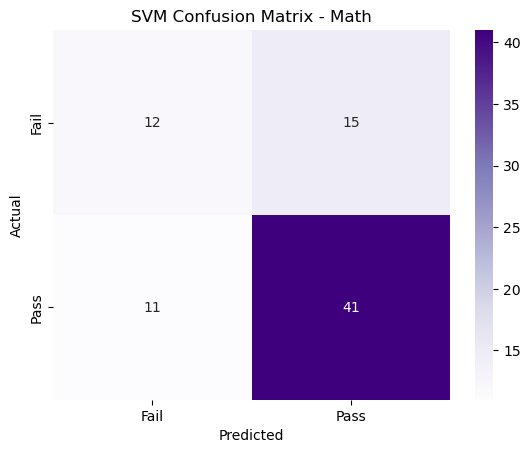

In [23]:
svm_math_model, X_test_math, y_test_math, y_pred_math, math_acc = train_svm_model_return_test("student-mat.csv", "Math")


In [ ]:
#Macro Precision   = (Precision(Class 0) + Precision(Class 1)) / 2
#Weighted Precision = ((Number of Class 0 × Precision(Class 0)) + (Number of Class 1 × Precision(Class 1))) / (Number of Class 0 + Number of Class 1)



=== SVM Training Report for Portuguese Dataset ===

Dataset BEFORE Label Encoding:
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  reason guardian  traveltime  studytime  failures schoolsup famsup paid activities nursery higher internet romantic  famrel  freetime  goout  Dalc  Walc  health  absences  pass
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  course   mother           2          2         0       yes     no   no         no     yes    yes       no       no       4         3      4     1     1       3         4     1
1     GP   F   17       U     GT3       T     1     1  at_home     other  course   father           1          2         0        no    yes   no         no      no    yes      yes       no       5         3      3     1     1       3         2     1
2     GP   F   15       U     LE3       T     1     1  at_home     other   other   mother           1          2         0       yes     no   no         no     yes   

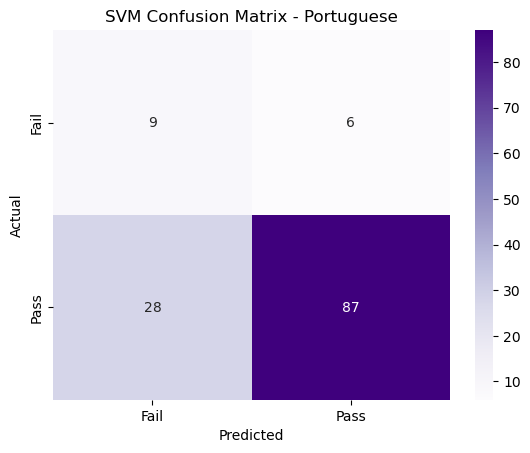

In [24]:
svm_model, X_test_svm, y_test_svm, y_pred_svm, svm_acc = train_svm_model_return_test("student-por.csv", "Portuguese")


|                 | Predicted Fail      | Predicted Pass      |
| --------------- | ------------------- | ------------------- |
| **Actual Fail** | True Negative (TN)  | False Positive (FP) |
| **Actual Pass** | False Negative (FN) | True Positive (TP)  |


# Random Forest Model

In [25]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

def train_model_return_test(csv_file, subject_name, test_size=0.2, random_state=42):
    print(f"\n=== Training Report for {subject_name} Dataset ===")

    data = pd.read_csv(csv_file, sep=";")

    # Create binary target
    data['pass'] = (data['G3'] >= 10).astype(int)

    # Drop G1, G2, G3
    data = data.drop(['G1','G2','G3'], axis=1)

    print("\nDataset BEFORE Label Encoding:")
    with pd.option_context('display.max_columns', None, 'display.width', 1000):
        print(data.head())


    categorical_cols = data.select_dtypes(include=['object']).columns
    le = LabelEncoder()
    for col in categorical_cols:
        data[col] = le.fit_transform(data[col])


    print("\nDataset AFTER Label Encoding:")
    with pd.option_context('display.max_columns', None, 'display.width', 1000):
        print(data.head())

    # Features and target
    X = data.drop('pass', axis=1)  # input features
    y = data['pass']   # To be predicted

    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )

    # Train Random Forest
    rf = RandomForestClassifier(random_state=random_state)
    rf.fit(X_train, y_train)

    # Predictions
    y_pred = rf.predict(X_test)

    # Evaluation
    acc = accuracy_score(y_test, y_pred)
    print(f"\nAccuracy: {acc:.4f}")
    print("\nClassification Report:\n", classification_report(y_test, y_pred))

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Fail','Pass'], yticklabels=['Fail','Pass'])
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix - {subject_name}")
    plt.show()

    return rf, X_test, y_test, y_pred, acc



=== Training Report for Portuguese Dataset ===

Dataset BEFORE Label Encoding:
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  reason guardian  traveltime  studytime  failures schoolsup famsup paid activities nursery higher internet romantic  famrel  freetime  goout  Dalc  Walc  health  absences  pass
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  course   mother           2          2         0       yes     no   no         no     yes    yes       no       no       4         3      4     1     1       3         4     1
1     GP   F   17       U     GT3       T     1     1  at_home     other  course   father           1          2         0        no    yes   no         no      no    yes      yes       no       5         3      3     1     1       3         2     1
2     GP   F   15       U     LE3       T     1     1  at_home     other   other   mother           1          2         0       yes     no   no         no     yes    yes

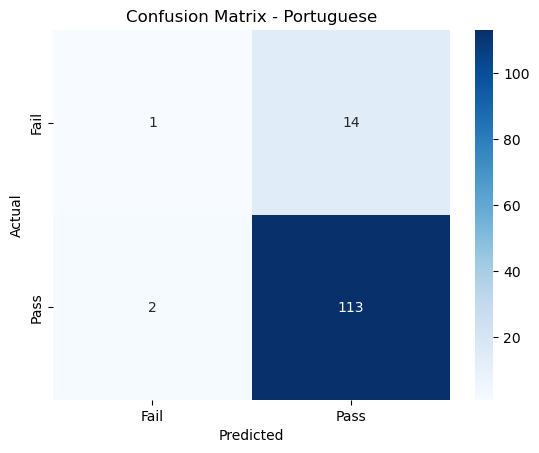

In [26]:

por_model, X_test_por, y_test_por, y_pred_por, por_acc = train_model_return_test("student-por.csv", "Portuguese")


=== Training Report for Math Dataset ===

Dataset BEFORE Label Encoding:
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  reason guardian  traveltime  studytime  failures schoolsup famsup paid activities nursery higher internet romantic  famrel  freetime  goout  Dalc  Walc  health  absences  pass
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  course   mother           2          2         0       yes     no   no         no     yes    yes       no       no       4         3      4     1     1       3         6     0
1     GP   F   17       U     GT3       T     1     1  at_home     other  course   father           1          2         0        no    yes   no         no      no    yes      yes       no       5         3      3     1     1       3         4     0
2     GP   F   15       U     LE3       T     1     1  at_home     other   other   mother           1          2         3       yes     no  yes         no     yes    yes      

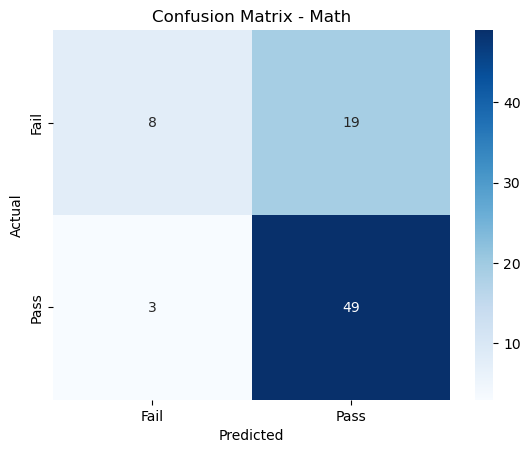

In [27]:

math_model, X_test_math, y_test_math, y_pred_math, math_acc = train_model_return_test("student-mat.csv", "Math")


In [ ]:
#Comparing accuracy for SVM and Random Forest

from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# --- Accuracy ---
print("=== Portuguese Dataset ===")
print("SVM Accuracy:", accuracy_score(y_test_svm, y_pred_svm))
print("Random Forest Accuracy:", accuracy_score(y_test_por, y_pred_por))




=== Portuguese Dataset ===
SVM Accuracy: 0.7384615384615385
Random Forest Accuracy: 0.8769230769230769


As Accuracy and other metrics are better with random forest model we will proceed with that

In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


comparison = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Math': [
        accuracy_score(y_test_math, y_pred_math),
        precision_score(y_test_math, y_pred_math),
        recall_score(y_test_math, y_pred_math),
        f1_score(y_test_math, y_pred_math)
    ],
    'Portuguese': [
        accuracy_score(y_test_por, y_pred_por),
        precision_score(y_test_por, y_pred_por),
        recall_score(y_test_por, y_pred_por),
        f1_score(y_test_por, y_pred_por)
    ]
}

comparison_df = pd.DataFrame(comparison)
print("\n=== Model Comparison ===")
print(comparison_df)


=== Model Comparison ===
      Metric      Math  Portuguese
0   Accuracy  0.721519    0.876923
1  Precision  0.720588    0.889764
2     Recall  0.942308    0.982609
3   F1-Score  0.816667    0.933884


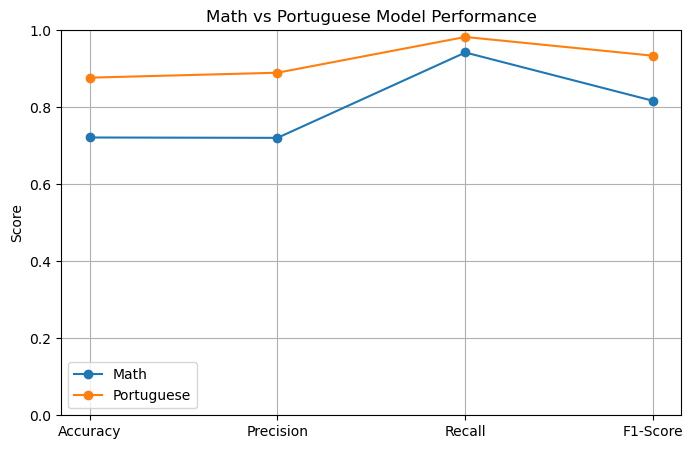

In [ ]:
import matplotlib.pyplot as plt

metrics = comparison_df['Metric']
math_scores = comparison_df['Math']
por_scores = comparison_df['Portuguese']

plt.figure(figsize=(8,5))
plt.plot(metrics, math_scores, marker='o', label='Math')
plt.plot(metrics, por_scores, marker='o', label='Portuguese')
plt.ylim(0, 1)     #limit for y axis
plt.title("Math vs Portuguese Model Performance")
plt.ylabel("Score")
plt.grid(True)
plt.legend()
plt.show()

# **As Portugese dataset has better metrics and datasize compared to Math dataset we will use it for further work.**

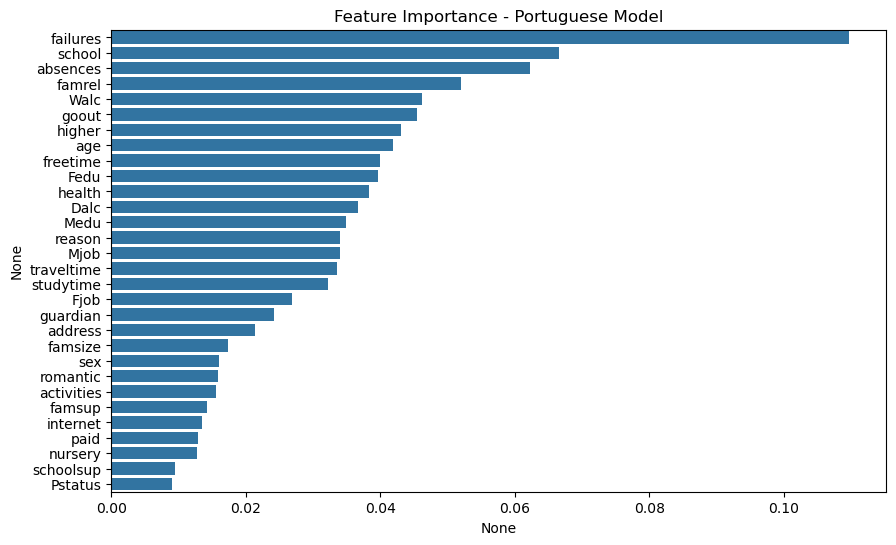

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# For Portuguese model
feat_importances = pd.Series(por_model.feature_importances_, index=X_test_por.columns)
feat_importances = feat_importances.sort_values(ascending=False)

plt.figure(figsize=(10,6))
sns.barplot(x=feat_importances, y=feat_importances.index)
plt.title("Feature Importance - Portuguese Model")
plt.show()


In [ ]:
import pandas as pd


df = pd.read_csv("student-por.csv", sep=';')

top_features = ['failures', 'school', 'absences', 'famrel', 'Walc',
                'goout', 'higher', 'age', 'freetime', 'Fedu']

# Print unique values
for feature in top_features:
    print(f"\nFeature: {feature}")
    print(df[feature].unique())


Feature: failures
[0 3 1 2]

Feature: school
['GP' 'MS']

Feature: absences
[ 4  2  6  0 10  8 16 14  1 12 24 22 32 30 21 15  9 18 26  7 11  5 13  3]

Feature: famrel
[4 5 3 1 2]

Feature: Walc
[1 3 2 4 5]

Feature: goout
[4 3 2 1 5]

Feature: higher
['yes' 'no']

Feature: age
[18 17 15 16 19 22 20 21]

Feature: freetime
[3 2 4 1 5]

Feature: Fedu
[4 1 2 3 0]


# Drop school (because it’s tied to a region/institution).

 Everything else (failures, absences, famrel, Walc, goout, higher, age, freetime, Fedu) is generalizable and fine to keep.

In [36]:
# Get top 11 features
top11_features = feat_importances.head(11).index.tolist()

if "school" in top11_features:
    top11_features.remove("school")

# Take the first 10
top_features = top11_features[:10]

print("Adjusted Top 10 Features (without school):", top_features)

# Print unique values
for feature in top_features:
    print(f"\nUnique values in '{feature}':")
    print(df[feature].unique())


Adjusted Top 10 Features (without school): ['failures', 'absences', 'famrel', 'Walc', 'goout', 'higher', 'age', 'freetime', 'Fedu', 'health']

Unique values in 'failures':
[0 3 1 2]

Unique values in 'absences':
[ 4  2  6  0 10  8 16 14  1 12 24 22 32 30 21 15  9 18 26  7 11  5 13  3]

Unique values in 'famrel':
[4 5 3 1 2]

Unique values in 'Walc':
[1 3 2 4 5]

Unique values in 'goout':
[4 3 2 1 5]

Unique values in 'higher':
['yes' 'no']

Unique values in 'age':
[18 17 15 16 19 22 20 21]

Unique values in 'freetime':
[3 2 4 1 5]

Unique values in 'Fedu':
[4 1 2 3 0]

Unique values in 'health':
[3 5 1 2 4]


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Prepare dataset with adjusted top features
X_top = X_test_por[top_features]
y_top = y_test_por

# Split dataset
X_train_top, X_test_top, y_train_top, y_test_top = train_test_split(
    X_top, y_top, test_size=0.2, random_state=42, stratify=y_top
)

# Train Random Forest with class_weight balanced
rf_top = RandomForestClassifier(random_state=42, class_weight="balanced")
rf_top.fit(X_train_top, y_train_top)

# Predictions (class labels)
y_pred_top = rf_top.predict(X_test_top)

# Predictions (probabilities)
y_proba_top = rf_top.predict_proba(X_test_top)  

# Store metrics
metrics_top10 = {
    'accuracy': accuracy_score(y_test_top, y_pred_top),
    'precision': precision_score(y_test_top, y_pred_top, zero_division=0),
    'recall': recall_score(y_test_top, y_pred_top, zero_division=0),
    'f1_score': f1_score(y_test_top, y_pred_top, zero_division=0),
    'classification_report': classification_report(y_test_top, y_pred_top, zero_division=0)
}

# Print metrics
print("\n=== Evaluation Metrics (Adjusted Top 10 Features) ===")
print(f"Accuracy : {metrics_top10['accuracy']:.4f}")
print(f"Precision: {metrics_top10['precision']:.4f}")
print(f"Recall   : {metrics_top10['recall']:.4f}")
print(f"F1-Score : {metrics_top10['f1_score']:.4f}")
print("\nDetailed Classification Report:\n", metrics_top10['classification_report'])

# show predicted class and probability for first 5 test samples
for i in range(5):
    pred_class = y_pred_top[i]
    pass_prob = y_proba_top[i][1]  # probability of "pass" class (1)
    fail_prob = y_proba_top[i][0]  # probability of "fail" class (0)
    print(f"Sample {i+1} -> Prediction: {pred_class}, Pass Probability: {pass_prob:.2f}, Fail Probability: {fail_prob:.2f}")



=== Evaluation Metrics (Adjusted Top 10 Features) ===
Accuracy : 0.8846
Precision: 0.8846
Recall   : 1.0000
F1-Score : 0.9388

Detailed Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00         3
           1       0.88      1.00      0.94        23

    accuracy                           0.88        26
   macro avg       0.44      0.50      0.47        26
weighted avg       0.78      0.88      0.83        26

Sample 1 -> Prediction: 1, Pass Probability: 0.94, Fail Probability: 0.06
Sample 2 -> Prediction: 1, Pass Probability: 0.95, Fail Probability: 0.05
Sample 3 -> Prediction: 1, Pass Probability: 0.85, Fail Probability: 0.15
Sample 4 -> Prediction: 1, Pass Probability: 0.91, Fail Probability: 0.09
Sample 5 -> Prediction: 1, Pass Probability: 0.87, Fail Probability: 0.13


In [ ]:
import pandas as pd

feature_names = X_top.columns

# Sample inputs
samples = [
    [0, 2, 5, 1, 1, 1, 17, 4, 4, 5],  
    [3, 20, 1, 5, 5, 0, 19, 1, 0, 1], 
    [1, 10, 3, 3, 3, 1, 18, 3, 2, 3], 
    [2, 5, 4, 2, 2, 1, 17, 2, 3, 4]   
]

# Predict class and probabilities for each sample
for i, sample in enumerate(samples):
    sample_df = pd.DataFrame([sample], columns=feature_names)
    pred_class = rf_top.predict(sample_df)[0]
    pred_proba = rf_top.predict_proba(sample_df)[0]  # [fail_prob, pass_prob]
    print(f"Sample {i+1} Prediction: {pred_class}, Pass Probability: {pred_proba[1]:.2f}, Fail Probability: {pred_proba[0]:.2f}")


Sample 1 Prediction: 1, Pass Probability: 0.82, Fail Probability: 0.18
Sample 2 Prediction: 0, Pass Probability: 0.44, Fail Probability: 0.56
Sample 3 Prediction: 1, Pass Probability: 0.89, Fail Probability: 0.11
Sample 4 Prediction: 1, Pass Probability: 0.87, Fail Probability: 0.13


In [44]:
from sklearn.ensemble import RandomForestClassifier
from joblib import dump

# Save the trained model as a joblib file
dump(rf_top, "student_prediction.joblib")
print("Model saved as student_prediction.joblib")


Model saved as student_prediction.joblib


-------------Final Model Used for further website creation.-------------------------




### Final Model for React website

